In [5]:
import scanpy as sc 
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
print("Environment ready")

c:\Users\murak\miniconda3\envs\scRNA\Lib\site-packages\h5py\__init__.py:36: UserWarning: h5py is running against HDF5 2.2.0 when it was built against 2.1.0, this may cause problems
  _warn(("h5py is running against HDF5 {0} when it was built against {1}, "


Environment ready


In [6]:
adata = sc.datasets.pbmc3k()
adata

AnnData object with n_obs × n_vars = 2700 × 32738
    var: 'gene_ids'

In [7]:
# look at the cell info
adata.obs.head()

""
index
AAACATACAACCAC-1
AAACATTGAGCTAC-1
AAACATTGATCAGC-1
AAACCGTGCTTCCG-1
AAACCGTGTATGCG-1


In [8]:
# look at the gene info 
adata.var.head()

,gene_ids
index,
MIR1302-10,ENSG00000243485
FAM138A,ENSG00000237613
OR4F5,ENSG00000186092
RP11-34P13.7,ENSG00000238009
RP11-34P13.8,ENSG00000239945


In [9]:
adata



AnnData object with n_obs × n_vars = 2700 × 32738
    var: 'gene_ids'

In [10]:
type(adata)

anndata._core.anndata.AnnData

In [11]:
adata.X[:5,:5].toarray()

array([[0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0.]], dtype=float32)

In [12]:
sc.pp.calculate_qc_metrics(adata, inplace=True)

In [13]:
adata.obs.head()

,n_genes_by_counts,log1p_n_genes_by_counts,total_counts,log1p_total_counts,pct_counts_in_top_50_genes,pct_counts_in_top_100_genes,pct_counts_in_top_200_genes,pct_counts_in_top_500_genes
index,,,,,,,,
AAACATACAACCAC-1,781,6.661855,2421.0,7.792349,47.748864,63.279637,74.969021,88.393226
AAACATTGAGCTAC-1,1352,7.210080,4903.0,8.497807,45.502753,61.023863,71.813176,82.622884
AAACATTGATCAGC-1,1131,7.031741,3149.0,8.055158,41.314703,53.794856,65.449349,79.961893
AAACCGTGCTTCCG-1,960,6.867974,2639.0,7.878534,39.029936,52.898825,66.691929,82.569155
AAACCGTGTATGCG-1,522,6.259581,981.0,6.889591,44.852192,55.657492,67.176351,97.757390


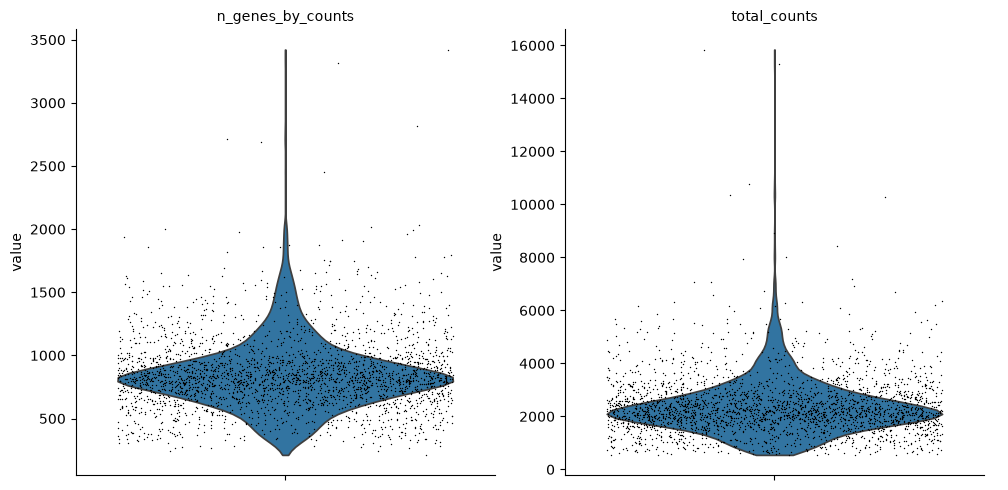

In [14]:
# plotting the number of genes detected in each cell shows us that most cells express about 900 genes and few express a lot more 
# it also shows us that most cells have about 2000 transcripts and few have more than that
# this plots the data from 2 cols in adata.obs
sc.pl.violin(
    adata, 
    ["n_genes_by_counts", "total_counts"], 
    jitter=0.4, 
    multi_panel=True
)

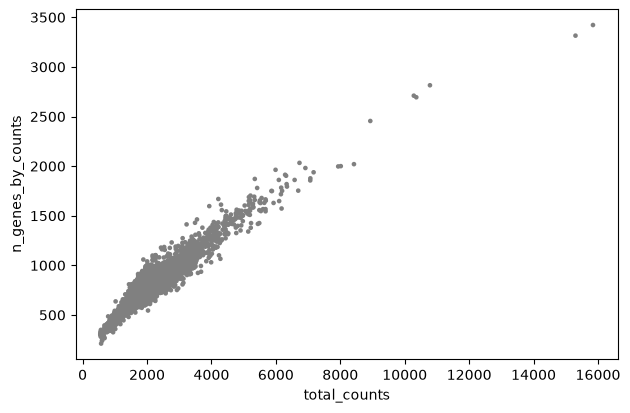

In [15]:
sc.pl.scatter(
    adata,
    x="total_counts",
    y="n_genes_by_counts"
)
# the more rna molecules there are the more genes they express, but they're clustered in a certain range

In [16]:
# since obs is a pd df, you use 2 brackets to select 2 cols 
# describe takes those 2 cols and tells you metrics for all cells
# count tells you the number of cells, mean tells how many genes on average each cell expresses, and how many rnas seen in each cell on average 

adata.obs[["n_genes_by_counts", "total_counts"]].describe()


,n_genes_by_counts,total_counts
count,2700.000000,2700.000000
mean,846.994074,2366.900391
std,282.104964,1094.262085
min,212.000000,548.000000
25%,690.000000,1757.750000
50%,817.000000,2197.000000
75%,953.250000,2763.000000
max,3422.000000,15844.000000


In [17]:
# creates a new col in var called mt that takes all the mt genes and their data
adata.var["mt"] = adata.var_names.str.startswith("MT")

# calculates qc metrics on the mt genes 
sc.pp.calculate_qc_metrics(
    adata,
    qc_vars=["mt"],  
    inplace=True
)

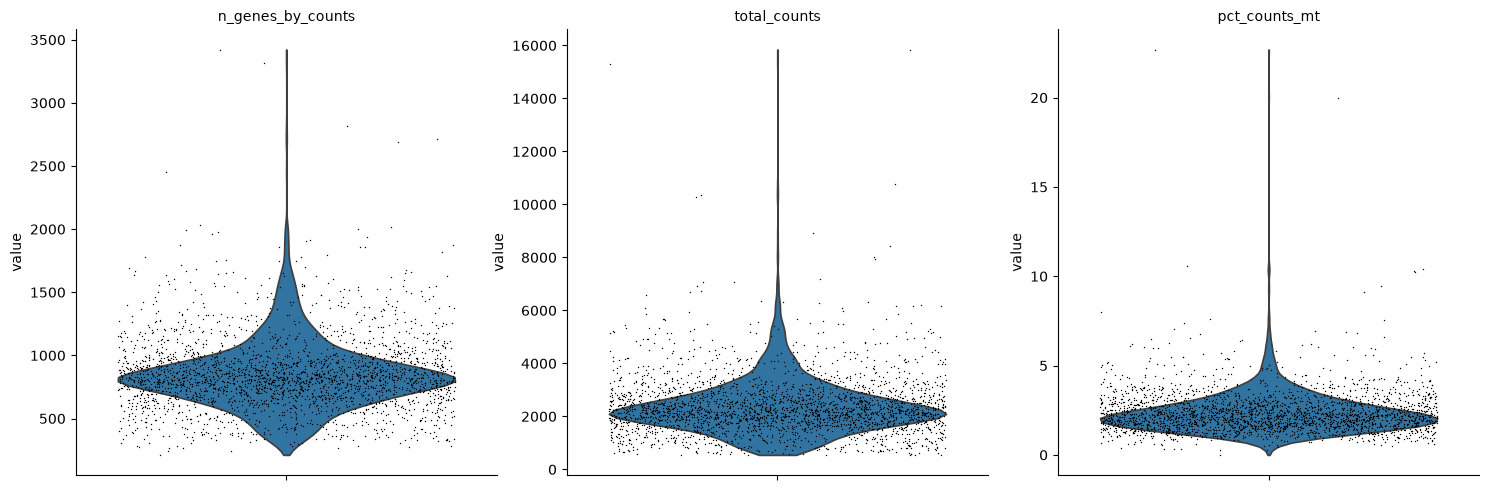

In [18]:
# scanpy searches for the df .obs only for .violin
sc.pl.violin(
    adata, 
    ["n_genes_by_counts", "total_counts", "pct_counts_mt"], 
    jitter=0.4, 
    multi_panel=True
)
# i notice that most cells have 900 genes in them
# most cells have 2000 rna molecules in them 
# most cells have 3% mt genes making up all genes 

In [19]:
# gives stats for pct counts of mt rna across all cells 
adata.obs["pct_counts_mt"].describe()
# avg 2.3% mtrna, std is 1.1, some have no mtrna, 75% is 2.7 and the max is really high at 22 

count    2700.000000
mean        2.356714
std         1.175540
min         0.000000
25%         1.655864
50%         2.168459
75%         2.797307
max        22.689075
Name: pct_counts_mt, dtype: float64

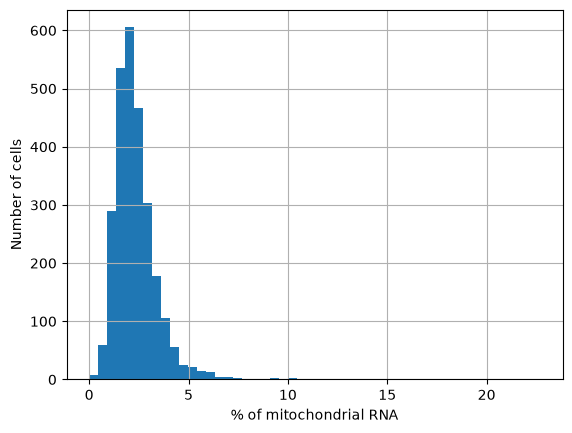

In [20]:
adata.obs["pct_counts_mt"].hist(bins=50)
plt.xlabel("% of mitochondrial RNA")
plt.ylabel("Number of cells")
plt.show()

In [21]:
# save original count of cells 
n_before = adata.n_obs

# adjust what we care to see in adata
# keep cells that express at least 300 and no more than 2500 different genes and 
adata = adata[adata.obs.n_genes_by_counts > 300, :]
adata = adata[adata.obs.n_genes_by_counts < 2500, :]

# also dropping cells that have too much rna (indicates low quality)
adata = adata[adata.obs.pct_counts_mt < 5, :]

# count after filtering
n_after = adata.n_obs

print(f"{n_before} cells before, {n_after} cells after")

2700 cells before, 2616 cells after


In [22]:
sc.pp.normalize_total(adata, target_sum=10000)
# target sum means the expression data is normalized so that if you add up all counts of rna molecules for each cell they'd be approx 10000

adata.obs["total_counts"].head()
# normalizing the data doesn't change total counts because its exists in the obs df not the X df

c:\Users\murak\miniconda3\envs\scRNA\Lib\site-packages\scanpy\preprocessing\_normalization.py:269: UserWarning: Received a view of an AnnData. Making a copy.
  view_to_actual(adata)


index
AAACATACAACCAC-1    2421.0
AAACATTGAGCTAC-1    4903.0
AAACATTGATCAGC-1    3149.0
AAACCGTGCTTCCG-1    2639.0
AAACCGTGTATGCG-1     981.0
Name: total_counts, dtype: float32

In [23]:
# lets see the X df to see the normalization
adata.X.sum(axis=1)
# adding up expression values across cols totals to 10000 bc each cell expresses approx 10000 molecules

matrix([[10000.   ],
        [10000.   ],
        [10000.   ],
        ...,
        [10000.001],
        [10000.   ],
        [10000.   ]], shape=(2616, 1), dtype=float32)

In [24]:
# make it a np arr and flatten it to a vector and show first 10
# all values are close to 10000 bc each cell expresses about the same rna 
np.array(adata.X.sum(axis=1)).flatten()[:10]

array([10000.   , 10000.   , 10000.   ,  9999.998,  9999.999, 10000.   ,
        9999.999, 10000.   , 10000.001, 10000.   ], dtype=float32)

In [25]:
# log transform adata to adjust large skewed values
# this makes large values smaller and small values bigger 
sc.pp.log1p(adata)

In [26]:
bef = adata.n_vars
sc.pp.highly_variable_genes(adata)
print(bef, adata.n_vars)
# adds new col called highly_variable which tells you if the gene varies across cell types or not
adata.var.head()


32738 32738


,gene_ids,n_cells_by_counts,mean_counts,log1p_mean_counts,pct_dropout_by_counts,total_counts,log1p_total_counts,mt,highly_variable,means,dispersions,dispersions_norm
index,,,,,,,,,,,,
MIR1302-10,ENSG00000243485,0,0.0,0.0,100.0,0.0,0.0,False,False,1.000000e-12,NaN,NaN
FAM138A,ENSG00000237613,0,0.0,0.0,100.0,0.0,0.0,False,False,1.000000e-12,NaN,NaN
OR4F5,ENSG00000186092,0,0.0,0.0,100.0,0.0,0.0,False,False,1.000000e-12,NaN,NaN
RP11-34P13.7,ENSG00000238009,0,0.0,0.0,100.0,0.0,0.0,False,False,1.000000e-12,NaN,NaN
RP11-34P13.8,ENSG00000239945,0,0.0,0.0,100.0,0.0,0.0,False,False,1.000000e-12,NaN,NaN


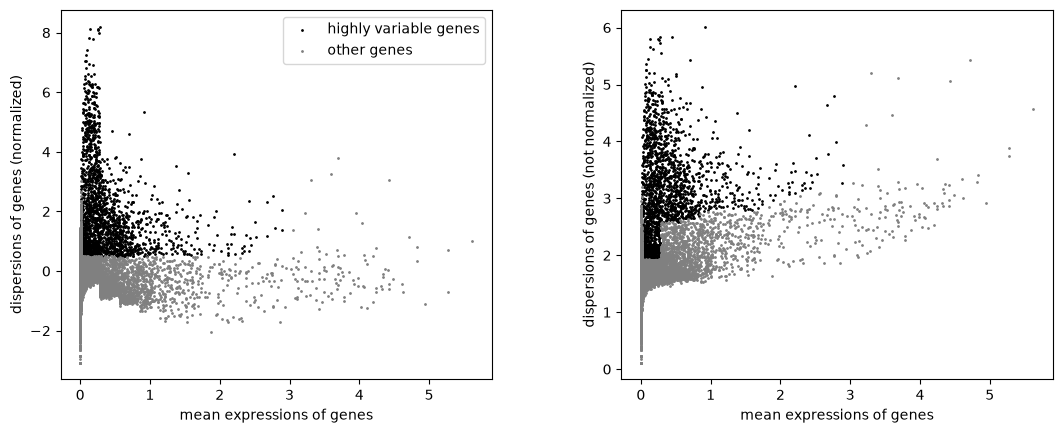

In [27]:
sc.pl.highly_variable_genes(adata)
# most genes are highly variable, many express around same range 
# y axis, the higher, the more variable the expression between T and B cells are, 
# the genes near the top might be best?
# the genes to the right are expressed most but we care more about how variable the genes are


In [28]:
# filter with just the highly variable genes
adata = adata[:, adata.var["highly_variable"]]
print(f"only {adata.n_vars} genes remain, there were {bef} before")


only 1987 genes remain, there were 32738 before


In [29]:
# we have 1987 features now, which is way less than 32k but we can still reduce it using pca
# pca will help us find pcs that capture the important insights 
sc.tl.pca(adata)
# view the np arr called X_pca stored in obsm, which is a container like a dict using [] for access
adata.obsm["X_pca"].shape
# there are 50 pcs and 2616 cells 


c:\Users\murak\miniconda3\envs\scRNA\Lib\site-packages\scanpy\preprocessing\_pca\__init__.py:384: ImplicitModificationWarning: Setting element `.obsm['X_pca']` of view, initializing view as actual.
  adata.obsm[key_obsm] = x_pca


(2616, 50)

In [30]:
# lets look at first 5 pcs
adata.obsm["X_pca"][:, 5]
# with these 50 pcs we have a cleaner feature space 

array([-1.2348565 ,  0.21610856,  1.0278516 , ...,  0.21295914,
        0.22194915, -0.8269927 ], shape=(2616,), dtype=float32)

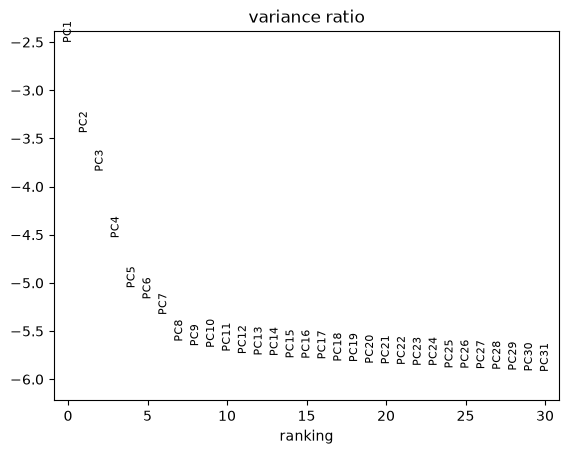

In [31]:
# lets use scree plot to visualize the pcs 
sc.pl.pca_variance_ratio(adata, log=True)

In [32]:
# cells that have similar expression should be near each other in a graph 
# we're going with 10 pcs to use some of the info the later pcs give too
# n_neighbors means find the 10 most similar cells for each cell, not all cells are shown
sc.pp.neighbors(adata, n_neighbors=10, n_pcs=10) 
adata.obsp.keys() # obsp means observation pair, how pairs of cells relate to each other 


c:\Users\murak\miniconda3\envs\scRNA\Lib\site-packages\threadpoolctl.py:1226: RuntimeWarning: 
Found Intel OpenMP ('libiomp') and LLVM OpenMP ('libomp') loaded at
the same time. Both libraries are known to be incompatible and this
can cause random crashes or deadlocks on Linux when loaded in the
same Python program.
Using threadpoolctl may cause crashes or deadlocks. For more
information and possible workarounds, please see
    https://github.com/joblib/threadpoolctl/blob/master/multiple_openmp.md

  warnings.warn(msg, RuntimeWarning)


KeysView(PairwiseArrays with keys: distances, connectivities)

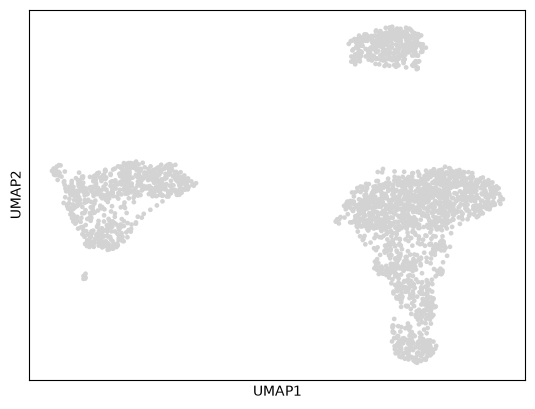

In [39]:
# UMAP 
sc.tl.umap(adata)
sc.pl.umap(adata)

In [43]:
sc.tl.leiden(adata)
adata.obs.head()

C:\Users\murak\AppData\Local\Temp\ipykernel_28212\2658440798.py:1: FutureWarning: In the future, the default backend for leiden will be igraph instead of leidenalg.

 To achieve the future defaults please pass: flavor="igraph" and n_iterations=2.  directed must also be False to work with igraph's implementation.
  sc.tl.leiden(adata)


,n_genes_by_counts,log1p_n_genes_by_counts,total_counts,log1p_total_counts,pct_counts_in_top_50_genes,pct_counts_in_top_100_genes,pct_counts_in_top_200_genes,pct_counts_in_top_500_genes,total_counts_mt,log1p_total_counts_mt,pct_counts_mt,leiden
index,,,,,,,,,,,,
AAACATACAACCAC-1,781,6.661855,2421.0,7.792349,47.748864,63.279637,74.969021,88.393226,75.0,4.330733,3.097893,4
AAACATTGAGCTAC-1,1352,7.210080,4903.0,8.497807,45.502753,61.023863,71.813176,82.622884,190.0,5.252274,3.875179,0
AAACATTGATCAGC-1,1131,7.031741,3149.0,8.055158,41.314703,53.794856,65.449349,79.961893,34.0,3.555348,1.079708,7
AAACCGTGCTTCCG-1,960,6.867974,2639.0,7.878534,39.029936,52.898825,66.691929,82.569155,52.0,3.970292,1.970443,5
AAACCGTGTATGCG-1,522,6.259581,981.0,6.889591,44.852192,55.657492,67.176351,97.757390,14.0,2.708050,1.427115,8


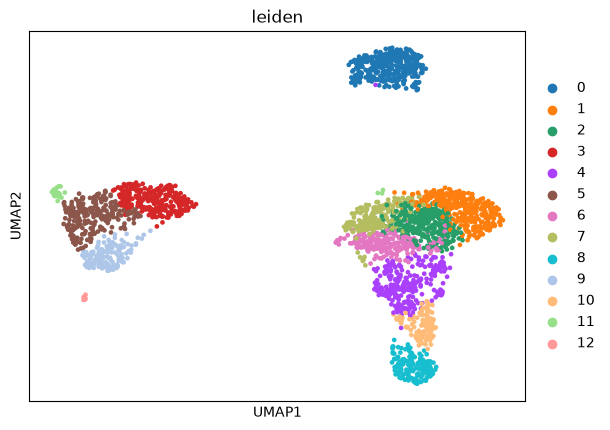

In [44]:
sc.pl.umap(
    adata, 
    color="leiden"
)

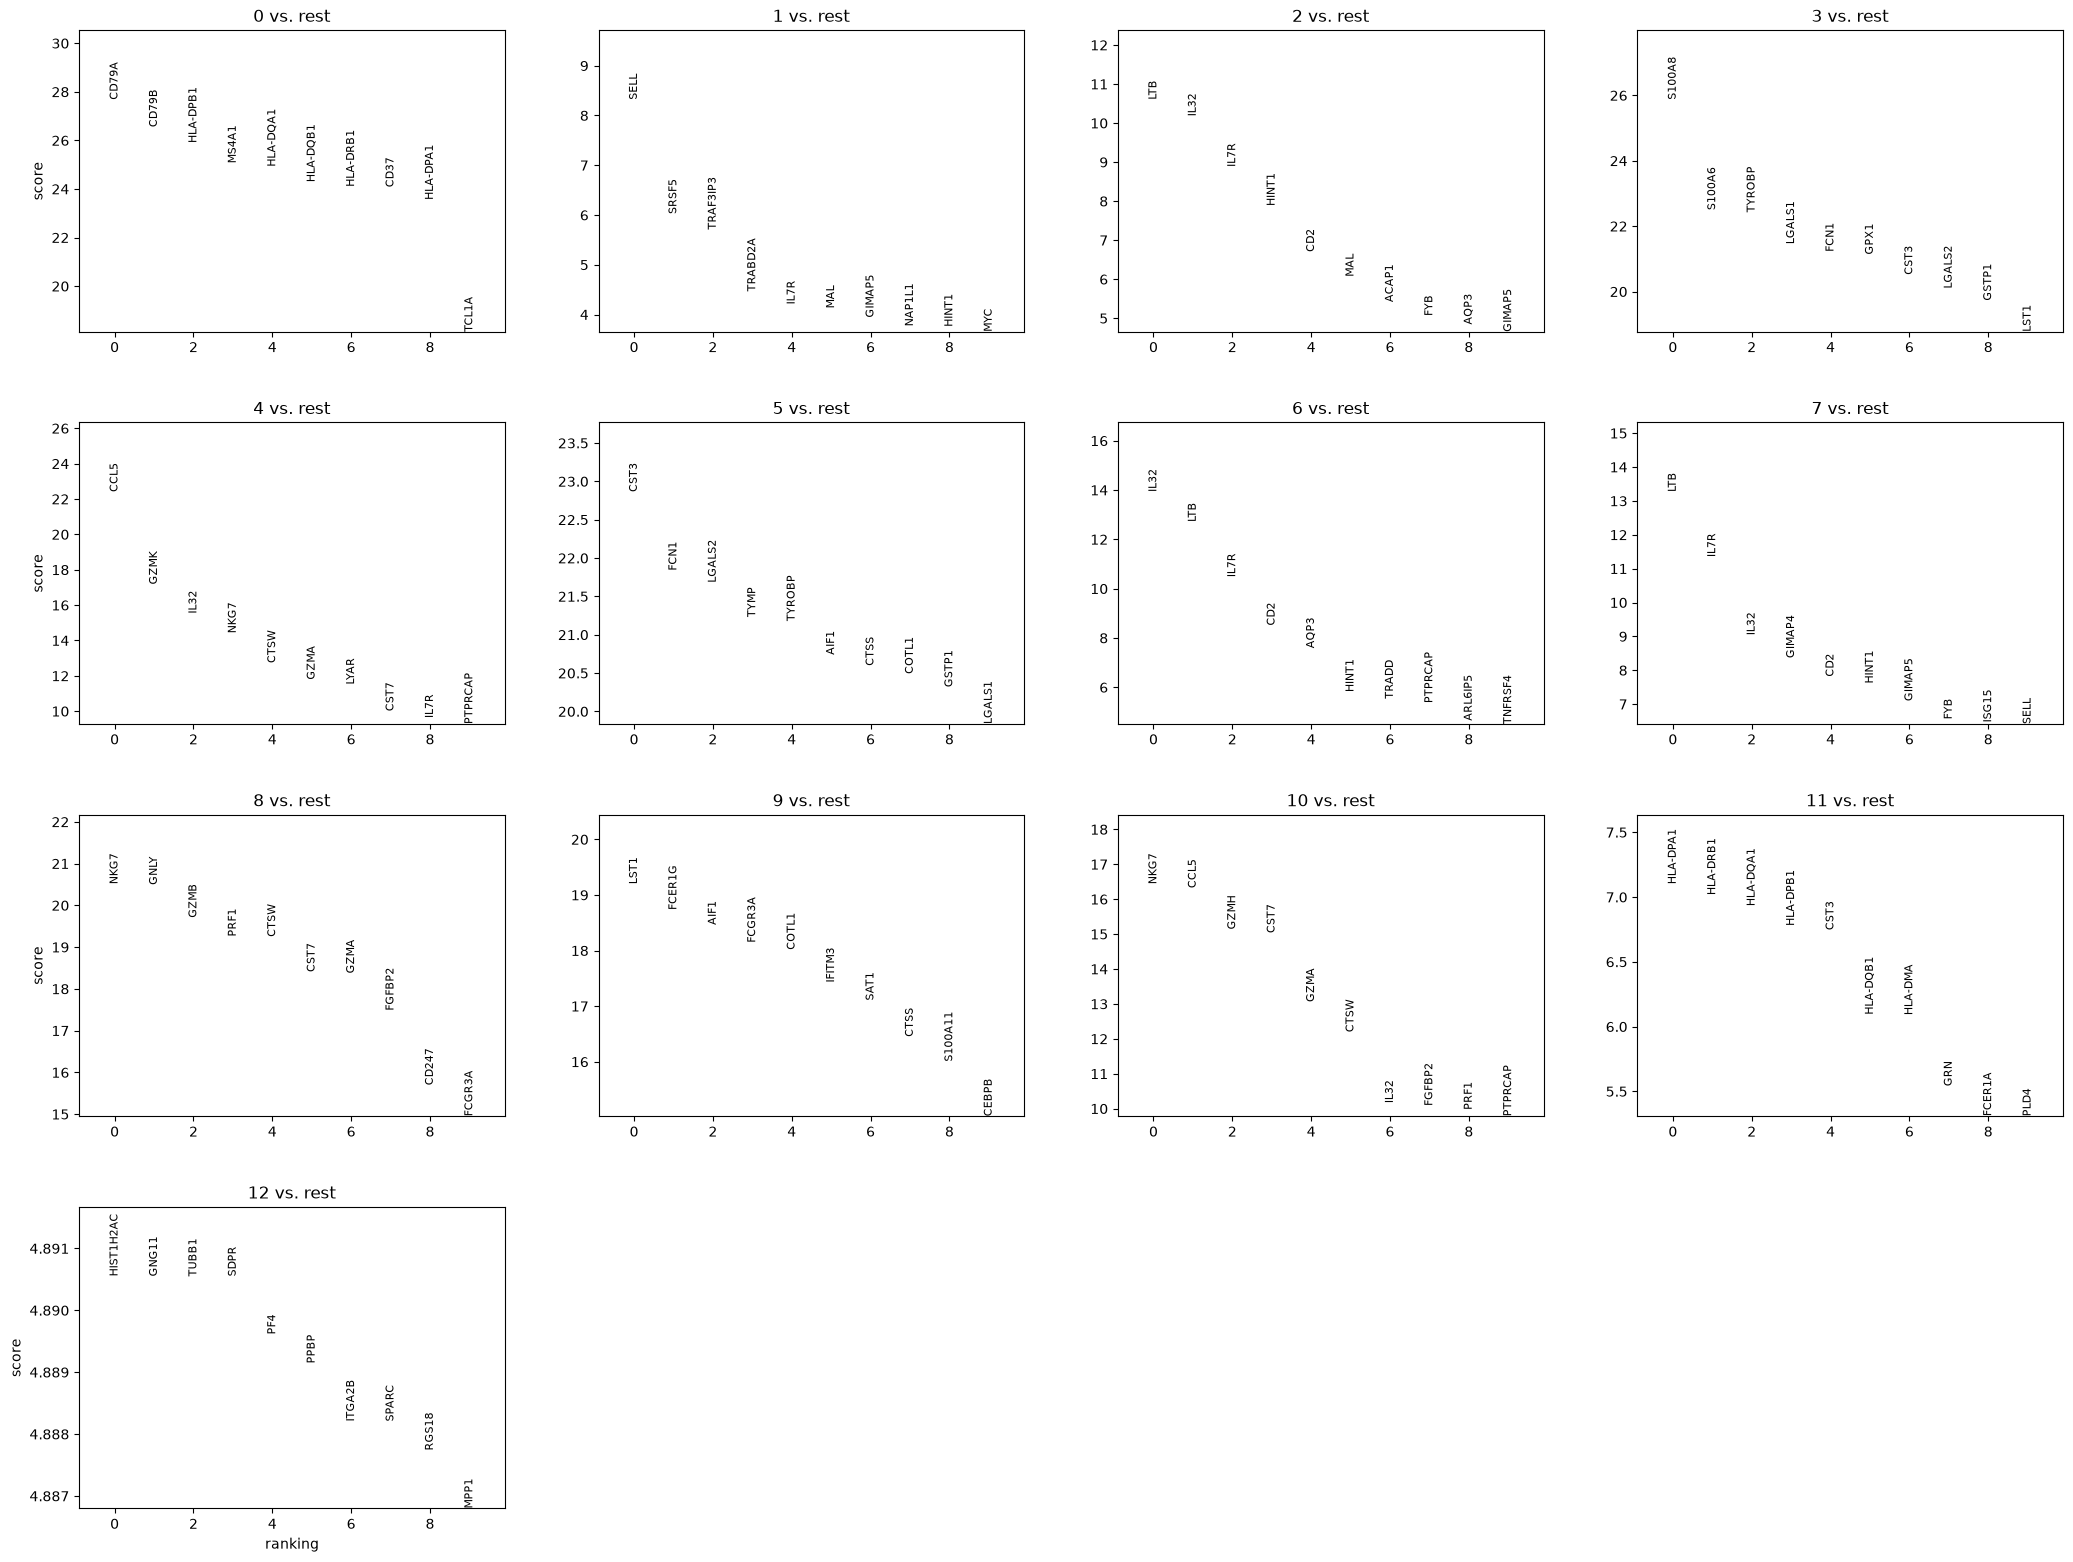

In [45]:
# this will tell us for each cluster which gene is highest expressed
sc.tl.rank_genes_groups(
    adata, 
    groupby="leiden", 
    method="wilcoxon"
)
sc.pl.rank_genes_groups(
    adata, 
    n_genes=10, 
    sharey=False
)

In [46]:
result = sc.get.rank_genes_groups_df(
    adata, 
    group=None
)
result.head()

,group,names,scores,logfoldchanges,pvals,pvals_adj
0,0,CD79A,27.674795,7.716732,1.404273e-168,2.790291e-165
1,0,CD79B,26.546518,5.553988,2.817242e-155,2.798930e-152
2,0,HLA-DPB1,25.892418,4.072172,8.106834e-148,5.369426e-145
3,0,MS4A1,25.057699,6.423985,1.439133e-138,7.148895e-136
4,0,HLA-DQA1,24.917364,5.313763,4.824401e-137,1.917217e-134


In [48]:
top5 = (
    result
    .sort_values(["group", "scores"], ascending=[True, False]) # sort group in ascending order and scores in descending
    .groupby("group") # groups each cluster
    .head(5) # shows top 5 genes for each cluster
)
top5

C:\Users\murak\AppData\Local\Temp\ipykernel_28212\3669956088.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("group") # groups each cluster


,group,names,scores,logfoldchanges,pvals,pvals_adj
0,0,CD79A,27.674795,7.716732,1.404273e-168,2.790291e-165
1,0,CD79B,26.546518,5.553988,2.817242e-155,2.798930e-152
2,0,HLA-DPB1,25.892418,4.072172,8.106834e-148,5.369426e-145
3,0,MS4A1,25.057699,6.423985,1.439133e-138,7.148895e-136
4,0,HLA-DQA1,24.917364,5.313763,4.824401e-137,1.917217e-134
...,...,...,...,...,...,...
23844,12,HIST1H2AC,4.890548,10.322406,1.005555e-06,1.540032e-04
23845,12,GNG11,4.890548,12.436696,1.005555e-06,1.540032e-04
23846,12,TUBB1,4.890548,11.289756,1.005555e-06,1.540032e-04
23847,12,SDPR,4.890548,12.220600,1.005555e-06,1.540032e-04


In [ ]:
top5[["group", "names"]] # pulls a subset of the df with cols group and names

,group,names
0,0,CD79A
1,0,CD79B
2,0,HLA-DPB1
3,0,MS4A1
4,0,HLA-DQA1
...,...,...
23844,12,HIST1H2AC
23845,12,GNG11
23846,12,TUBB1
23847,12,SDPR


In [57]:
characteristic_genes = {}
for i in range(13):
    genes = top5[top5["group"] == str(i)]["names"].tolist()
    characteristic_genes[i] = genes

print(characteristic_genes)

{0: ['CD79A', 'CD79B', 'HLA-DPB1', 'MS4A1', 'HLA-DQA1'], 1: ['SELL', 'SRSF5', 'TRAF3IP3', 'TRABD2A', 'IL7R'], 2: ['LTB', 'IL32', 'IL7R', 'HINT1', 'CD2'], 3: ['S100A8', 'S100A6', 'TYROBP', 'LGALS1', 'FCN1'], 4: ['CCL5', 'GZMK', 'IL32', 'NKG7', 'CTSW'], 5: ['CST3', 'FCN1', 'LGALS2', 'TYMP', 'TYROBP'], 6: ['IL32', 'LTB', 'IL7R', 'CD2', 'AQP3'], 7: ['LTB', 'IL7R', 'IL32', 'GIMAP4', 'CD2'], 8: ['NKG7', 'GNLY', 'GZMB', 'PRF1', 'CTSW'], 9: ['LST1', 'FCER1G', 'AIF1', 'FCGR3A', 'COTL1'], 10: ['NKG7', 'CCL5', 'GZMH', 'CST7', 'GZMA'], 11: ['HLA-DPA1', 'HLA-DRB1', 'HLA-DQA1', 'HLA-DPB1', 'CST3'], 12: ['HIST1H2AC', 'GNG11', 'TUBB1', 'SDPR', 'PF4']}


In [59]:
cluster_to_celltype = {
    "0": "B",
    "1": "Naive T", 
    "2": "T/CD4 T",
    "3": "Classical monocytes",
    "4": "Memory/effector T",
    "5": "Classical monocytes", 
    "6": "T/CD4 T",
    "7": "T/CD4 T",
    "8": "NK",
    "9": "FCGR3A+ monocytes", 
    "10": "NK/cytotoxic lymphocytes",
    "11": "Dendritic/antigen-presenting",
    "12": "Megakaryocytes",
}
# map the cluster numbers to the new labels
adata.obs["cell_type"] = adata.obs["leiden"].map(cluster_to_celltype)
adata.obs[["leiden", "cell_type"]].head(20)

,leiden,cell_type
index,,
AAACATACAACCAC-1,4,Memory/effector T
AAACATTGAGCTAC-1,0,B
AAACATTGATCAGC-1,7,T/CD4 T
AAACCGTGCTTCCG-1,5,Classical monocytes
AAACCGTGTATGCG-1,8,NK
AAACGCACTGGTAC-1,2,T/CD4 T
AAACGCTGACCAGT-1,4,Memory/effector T
AAACGCTGGTTCTT-1,4,Memory/effector T
AAACGCTGTAGCCA-1,4,Memory/effector T


In [ ]:
# for each cell type, count how many cells there are
adata.obs["cell_type"].value_counts()

cell_type
T/CD4 T                         738
Classical monocytes             509
B                               338
Naive T                         337
Memory/effector T               247
NK                              158
FCGR3A+ monocytes               141
NK/cytotoxic lymphocytes        117
Dendritic/antigen-presenting     23
Megakaryocytes                    8
Name: count, dtype: int64

Starting the ML portion...

In [62]:
X = adata.X
y = adata.obs["cell_type"]
X.shape

from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y, 
    test_size=.2,
    random_state=42,
    stratify=y # assigns labels with the same proportion as the train  y
)

from sklearn.linear_model import LogisticRegression
# create the model
model = LogisticRegression(
    max_iter=1000
)
# fit the model to X train and y train, it's learning now
model.fit(X_train, y_train)

# make prediction using X test
y_pred = model.predict(X_test)

# evaluate
from sklearn.metrics import accuracy_score
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy:.3f}")

Accuracy: 0.922
